# 3. Modelling and evaluation

**Prerequisite:** `aaqa train` has been run (it writes `models/forecaster.joblib` and `reports/metrics.json`).

Protocol:
- **Test**: the last 365 days, never seen in training (a year covers every season).
- Chronological **cross-validation** (`TimeSeriesSplit`, 5 folds) on the rest; never a random shuffle.
- **Baselines**: persistence ("tomorrow = today"), monthly climatology, Ridge regression.
- **Model**: `HistGradientBoostingRegressor` (absolute-error loss) on the D+h / D log-ratio, one per
  pollutant and horizon, plus two quantile models (10%, 90%) for the prediction interval.
- **Selection**: when the model does not beat persistence in cross-validation, persistence is served.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aaqa import config as paths
from aaqa.aqi import WHO_PM25_24H, WHO_PM25_ANNUAL
from aaqa.pipeline import load_daily, load_hourly
from aaqa.pollutants import POLLUTANTS

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.precision", 2)

In [2]:
metrics = json.loads(paths.METRICS_PATH.read_text())
rows = []
for key, by_h in metrics.items():
    for h, m in by_h.items():
        gb, pers = m["models"]["gradient_boosting"], m["models"]["persistence"]
        rows.append({"pollutant": POLLUTANTS[key].name, "horizon": f"D+{h}", "MAE model": gb["mae"],
                     "MAE persistence": pers["mae"], "gain (test)": gb["skill_vs_persistence"],
                     "gain (CV)": 1 - m["cv_mae_mean"] / m["cv_persistence_mae_mean"],
                     "80% coverage": m["interval_80_coverage"], "served": m["selected_method"]})
table = pd.DataFrame(rows).set_index(["pollutant", "horizon"])
table.style.format({"MAE model": "{:.2f}", "MAE persistence": "{:.2f}", "gain (test)": "{:+.0%}",
                    "gain (CV)": "{:+.0%}", "80% coverage": "{:.0%}"})

## PM2.5 in detail: every model compared

In [3]:
pd.DataFrame({f"D+{h}": {name: s["mae"] for name, s in m["models"].items()} | {
    "R² model": m["models"]["gradient_boosting"]["r2"],
    "right AQI category": m["models"]["gradient_boosting"]["aqi_category_accuracy"]}
    for h, m in metrics["pm2_5"].items()}).round(3)

,D+1,D+2,D+3
persistence,1.81,2.52,2.83
climatology,6.46,6.46,6.45
ridge,1.98,2.83,3.35
gradient_boosting,1.70,2.19,2.42
R² model,0.70,0.49,0.38
right AQI category,0.81,0.77,0.75


## D+1 forecast on the test year

/Users/Koss2kosS/git/AAQA/.venv/lib/python3.13/site-packages/pandas/plotting/_matplotlib/timeseries.py:414: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  xaxis.set_converter(PeriodConverter())
/Users/Koss2kosS/git/AAQA/.venv/lib/python3.13/site-packages/pandas/plotting/_matplotlib/timeseries.py:414: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  xaxis.set_converter(PeriodConverter())
/Users/Koss2kosS/git/AAQA/.venv/lib/python3.13/site-packages/pandas/plotting/_matplotlib/timeseries.py:414: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  xaxis.set_converter(PeriodConverter())
/Users/Koss2kosS/git/AAQA/.venv/lib/python3.13/site-packages/pandas/plotting/_matplotlib/timeseries.py:414: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  xaxis.set_conve

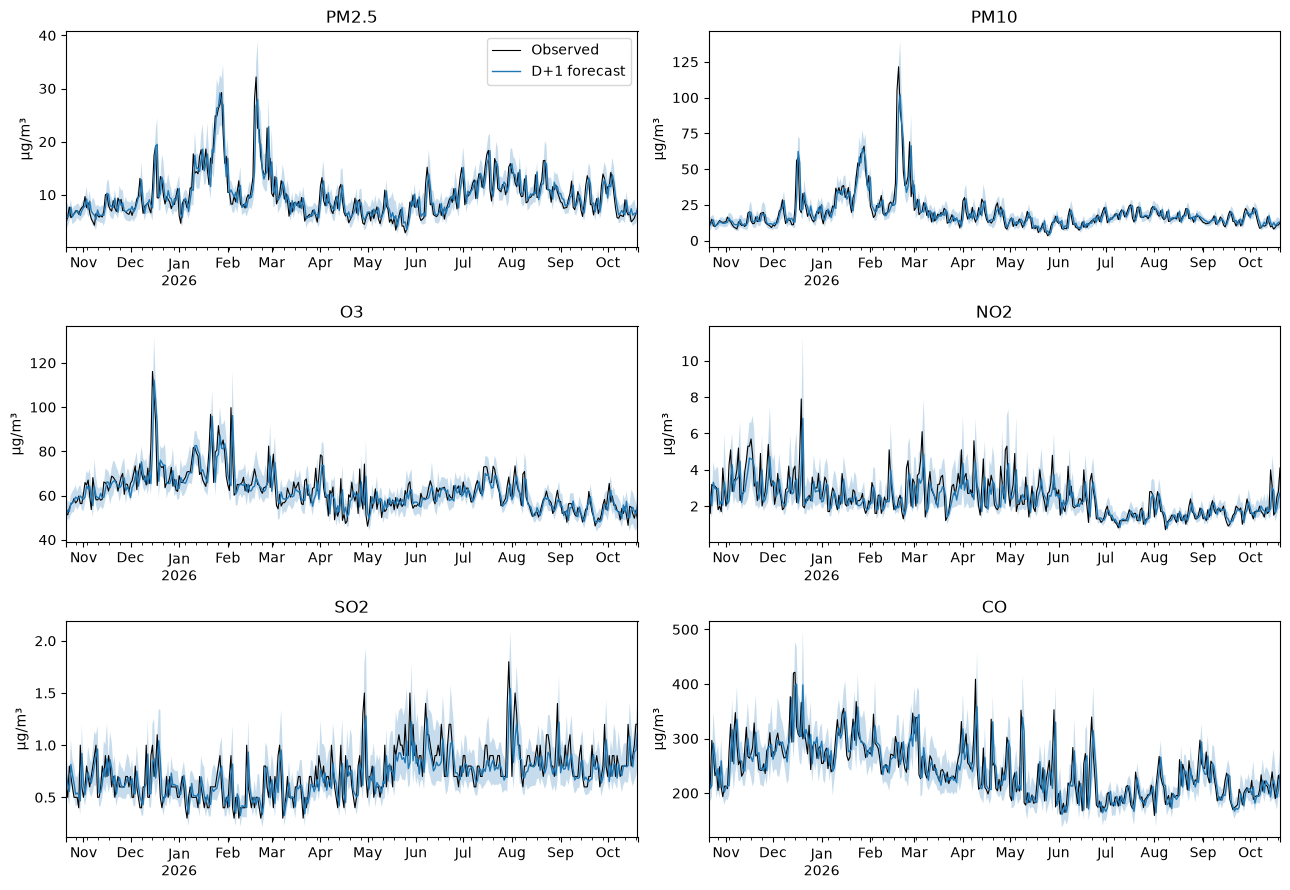

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9))
for ax, (key, spec) in zip(axes.ravel(), POLLUTANTS.items()):
    pred = pd.read_csv(paths.REPORTS_DIR / f"test_predictions_{key}_h1.csv", index_col=0, parse_dates=True)
    ax.fill_between(pred.index, pred["q10"], pred["q90"], alpha=0.25)
    pred["y_true"].plot(ax=ax, color="black", lw=0.8, label="Observed")
    pred["gradient_boosting"].plot(ax=ax, lw=1, label="D+1 forecast")
    ax.set(title=spec.name, xlabel="", ylabel="µg/m³")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

## PM2.5 error by month

In [5]:
pred = pd.read_csv(paths.REPORTS_DIR / "test_predictions_pm2_5_h1.csv", index_col=0, parse_dates=True)
err = (pred["gradient_boosting"] - pred["y_true"]).abs()
pers = (pred["persistence"] - pred["y_true"]).abs()
pd.DataFrame({"MAE model": err.groupby(err.index.month).mean(),
              "MAE persistence": pers.groupby(pers.index.month).mean()}).set_axis(MONTHS).round(2).T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
MAE model,2.42,2.92,1.58,1.61,1.39,1.67,1.88,1.63,1.57,1.08,1.10,1.67
MAE persistence,2.58,3.16,1.69,1.69,1.58,1.74,2.03,1.65,1.77,1.04,1.03,1.88


## Feature importance (permutation, D+1)

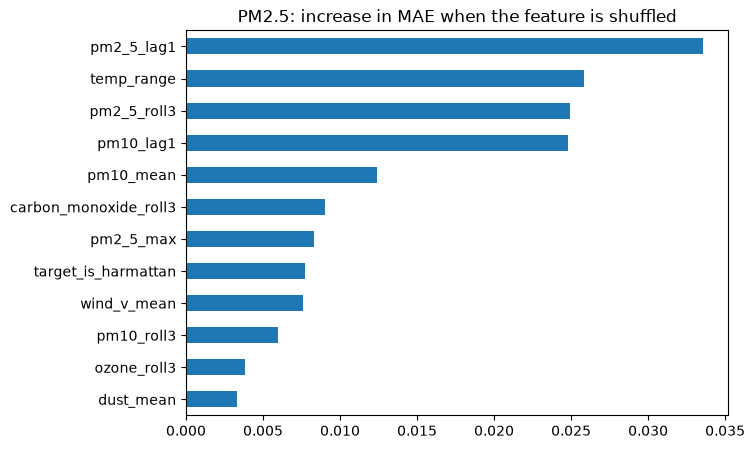

In [6]:
imp = pd.read_csv(paths.REPORTS_DIR / "feature_importance.csv", index_col=0)
imp.drop("pm2_5_mean")["pm2_5"].sort_values().tail(12).plot.barh(figsize=(7, 5), title="PM2.5: increase in MAE when the feature is shuffled"); plt.show()

Each pollutant's own day-D value dominates by construction: the model predicts the **relative** change
from that level, so shuffling it destroys the forecast. The plot above leaves it out; the other features
refine that change.

## Limitations
- **No ground measurements**: the target is itself CAMS model output. Validate with sensors (US
  Embassy, AirQo, PurpleAir) before any official use.
- The "80%" interval only covers 64–78% of cases: it is too narrow and needs recalibrating.
- Sudden harmattan episodes remain the hardest to anticipate beyond D+1.
- For gases (NO2, SO2, CO), CAMS values are very low and almost certainly underestimated.

In [7]:
from aaqa.models.predictor import AirQualityPredictor
forecast = AirQualityPredictor.load(paths.MODEL_PATH).forecast(load_daily())
pd.DataFrame({f["date"]: {p["name"]: f"{p['value']:.1f} ({p['label']})" for p in f["pollutants"]} | {"overall AQI": f["overall"]["aqi"]}
              for f in forecast["forecasts"]})

,2026-10-22,2026-10-23,2026-10-24
PM2.5,7.0 (Good),6.5 (Good),6.4 (Good)
PM10,12.7 (Good),13.1 (Good),11.3 (Good)
O3,51.9 (Good),52.2 (Good),52.5 (Good)
NO2,3.0 (Good),2.7 (Good),2.5 (Good)
SO2,1.2 (Good),1.2 (Good),1.2 (Good)
CO,222.5 (Good),219.8 (Good),219.2 (Good)
overall AQI,39,36,36
